In [25]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Enter your API key
api_key = "YOUR_API_KEY"

# Enter city name
city = "Ahmedabad"

# Fetch weather data
url = f"https://api.openweathermap.org/data/2.5/forecast?q={city}&appid={api_key}&units=metric"

response = requests.get(url)
data = response.json()

# Check API response
if response.status_code == 200:

    weather_data = []

    for item in data["list"]:
        weather_data.append({
            "Date": item["dt_txt"],
            "Temperature": item["main"]["temp"],
            "Humidity": item["main"]["humidity"],
            "Wind Speed": item["wind"]["speed"],
            "Weather": item["weather"][0]["description"]
        })

    df = pd.DataFrame(weather_data)

    print("Weather Data:")
    display(df.head())

else:
    print("Error:", data.get("message", "Unable to fetch weather data"))

Weather Data:


,Date,Temperature,Humidity,Wind Speed,Weather
0,2026-10-12 09:00:00,33.02,33,3.14,clear sky
1,2026-10-12 12:00:00,32.99,30,2.82,clear sky
2,2026-10-12 15:00:00,31.09,31,2.95,clear sky
3,2026-10-12 18:00:00,26.84,36,2.97,clear sky
4,2026-10-12 21:00:00,25.31,38,2.90,clear sky


In [27]:
df.shape

(40, 5)

In [28]:
# Display summary statistics
print("Statistical Summary:")
display(df[["Temperature", "Humidity", "Wind Speed"]].describe())

# Average weather conditions
print("Average Temperature:", df["Temperature"].mean(), "°C")
print("Average Humidity:", df["Humidity"].mean(), "%")
print("Average Wind Speed:", df["Wind Speed"].mean(), "m/s")

Statistical Summary:


,Temperature,Humidity,Wind Speed
count,40.000000,40.000000,40.000000
mean,31.601500,31.425000,1.932750
std,3.733109,5.882994,0.747958
min,23.850000,19.000000,0.280000
25%,29.355000,27.000000,1.525000
50%,31.120000,30.500000,1.940000
75%,35.202500,36.000000,2.542500
max,37.820000,43.000000,3.140000


Average Temperature: 31.601499999999998 °C
Average Humidity: 31.425 %
Average Wind Speed: 1.93275 m/s


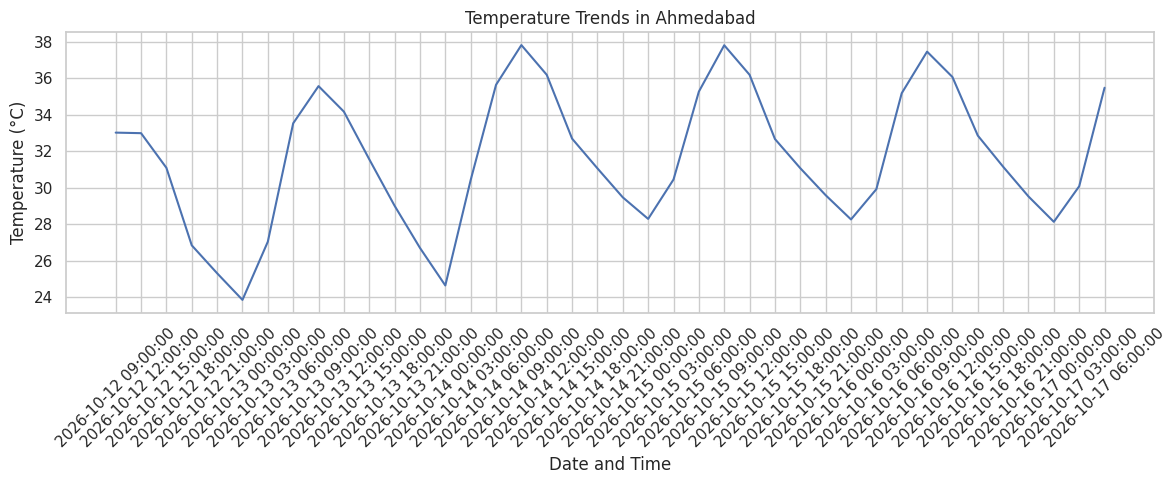

In [29]:
# Chart 1: Temperature Trend
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Temperature"])
plt.title("Temperature Trends in Ahmedabad")
plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

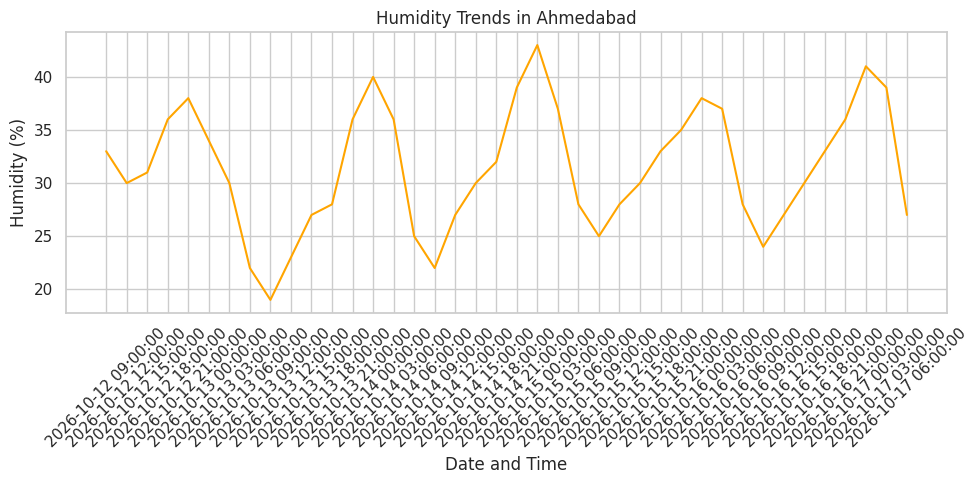

In [30]:
# Chart 2: Humidity Trend
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Humidity"], color="orange")
plt.title("Humidity Trends in Ahmedabad")
plt.xlabel("Date and Time")
plt.ylabel("Humidity (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

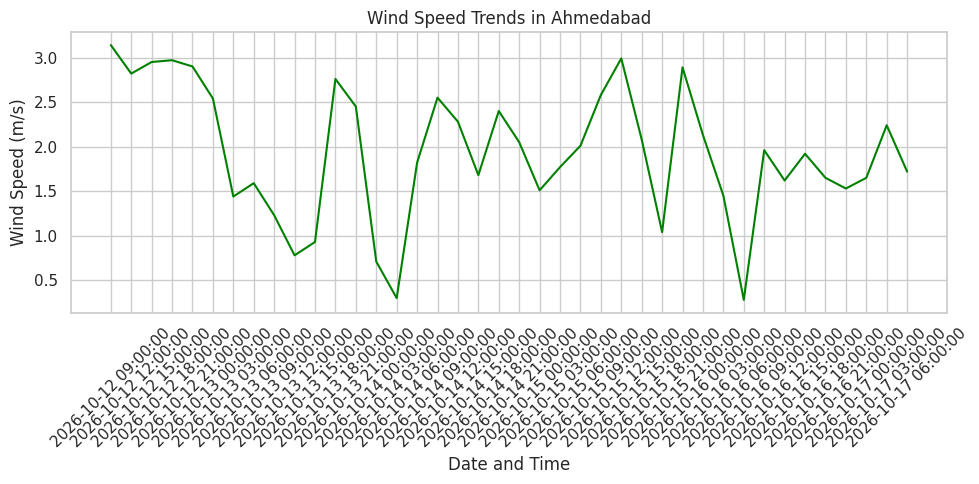

In [31]:
# Chart 3: Wind Speed Trend
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Wind Speed"], color="green")
plt.title("Wind Speed Trends in Ahmedabad")
plt.xlabel("Date and Time")
plt.ylabel("Wind Speed (m/s)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

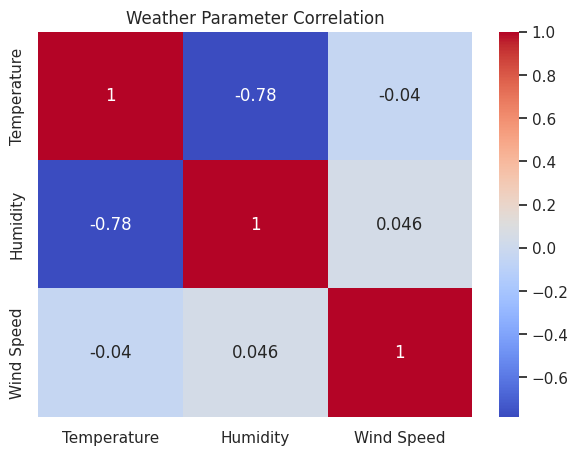

In [32]:
# Chart 4: Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[["Temperature", "Humidity", "Wind Speed"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Weather Parameter Correlation")
plt.show()